# Baseline: отток клиентов телеком-оператора

**ML PRO · подготовка.** Это выполненный ноутбук: читайте сверху вниз и запускайте ячейки. Ничего писать не нужно.

Здесь мы доводим датасет сквозного проекта до состояния «модель обучена, метрики посчитаны, артефакт сохранён». Ровно с этого места начинается лекция 1.1: *модель есть, что дальше?* На семинаре 12 сентября мы будем оборачивать в сервис именно этот артефакт.

План:
1. Загрузка и первый взгляд
2. Целевая переменная и дисбаланс
3. Пропуски и типы
4. Немного разведки
5. Разбиение на train и test
6. Baseline: Pipeline с логистической регрессией
7. CatBoost с ранней остановкой
8. Порог под бизнес-требование
9. Сохранение артефакта с метаданными
10. Загрузка и предсказание на одной строке

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, precision_score, recall_score, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
DATA_PATH = Path("data/telco_churn.csv")
ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)

## 1. Загрузка и первый взгляд

Датасет Telco Customer Churn: 7 043 клиента, 20 признаков и целевая переменная `Churn`. Один клиент это одна строка.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Обратите внимание на `TotalCharges`: pandas прочитал его как `object`, то есть как строки. Это первый сюрприз датасета, разберём в разделе 3.

## 2. Целевая переменная и дисбаланс

`Churn` это Yes/No. Переводим в 0/1 и смотрим на баланс классов: от него зависит выбор метрики.

In [4]:
df["churn"] = (df["Churn"] == "Yes").astype(int)
rate = df["churn"].mean()
print(f"Ушедших клиентов: {df['churn'].sum()} из {len(df)} ({rate:.1%})")
df["churn"].value_counts()

Ушедших клиентов: 1869 из 7043 (26.5%)


churn
0    5174
1    1869
Name: count, dtype: int64

Каждый четвёртый клиент уходит. Это умеренный дисбаланс: accuracy тут почти бесполезна (модель «никто не уйдёт» даст 73%), поэтому дальше смотрим ROC-AUC, PR-AUC и precision/recall при выбранном пороге.

## 3. Пропуски и типы

`TotalCharges` хранится строкой, потому что у новых клиентов (tenure = 0) там пробел. Приводим к числу: пробелы станут `NaN`, и это честно, а не ошибка.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("пропусков в TotalCharges:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head()

пропусков в TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN


Заполнять пропуски здесь руками не будем: это сделает `SimpleImputer` внутри Pipeline, и сделает одинаково на обучении и в сервисе. Ручная правка датафрейма в ноутбуке это как раз то, что потом не воспроизводится в проде.

## 4. Немного разведки

Два графика, чтобы почувствовать данные: доля оттока по типу контракта и распределение стажа для ушедших и оставшихся.

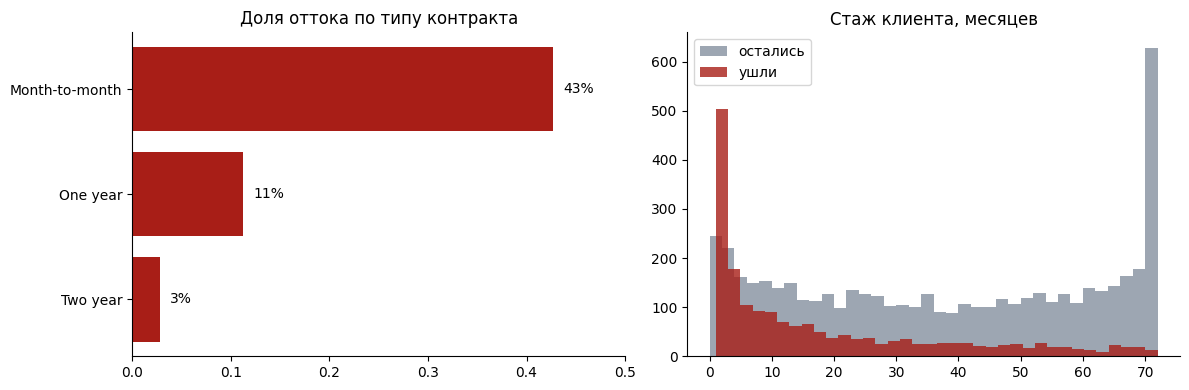

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_contract = df.groupby("Contract")["churn"].mean().sort_values()
axes[0].barh(by_contract.index, by_contract.values, color="#A81E17")
axes[0].set_title("Доля оттока по типу контракта")
axes[0].set_xlim(0, 0.5)
for i, v in enumerate(by_contract.values):
    axes[0].text(v + 0.01, i, f"{v:.0%}", va="center")

axes[1].hist(df.loc[df.churn == 0, "tenure"], bins=36, alpha=0.6, label="остались", color="#5C6B80")
axes[1].hist(df.loc[df.churn == 1, "tenure"], bins=36, alpha=0.8, label="ушли", color="#A81E17")
axes[1].set_title("Стаж клиента, месяцев")
axes[1].legend()
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Помесячный контракт уходит в разы чаще двухлетнего, а уходят в основном новички. Это и есть сигнал, который модель должна поймать. Ничего сложного: baseline на таких данных будет приличным.

## 5. Разбиение на train и test

Стратифицированное разбиение 80/20: доля оттока в обеих частях одинаковая. `customerID` в признаки не берём: идентификатор ничего не предсказывает, а модель по нему переобучится.

В этом датасете нет дат, поэтому делим случайно. В реальном сервисе оттока делили бы по времени: обучение на прошлом, проверка на будущем. Об этом в лекции 4.1.

In [7]:
TARGET = "churn"
DROP = ["customerID", "Churn", TARGET]
X = df.drop(columns=DROP)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print(f"доля оттока: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

(5634, 19) (1409, 19)
доля оттока: train 0.265, test 0.265


In [8]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("числовые:", numeric_cols)
print("категориальные:", categorical_cols)

числовые: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
категориальные: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6. Baseline: Pipeline с логистической регрессией

Вся предобработка живёт внутри `Pipeline`: импутация, масштабирование, one-hot. Это принципиально: `fit` вызывается один раз на train, а `transform` потом применяется к любой строке одинаково. Ровно этот объект целиком поедет в сервис, и там не нужно будет ничего пересчитывать руками.

In [9]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

logreg = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, C=1.0)),
])
logreg.fit(X_train, y_train)

def report(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    row = {
        "model": name,
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        f"precision@{threshold}": precision_score(y_true, pred),
        f"recall@{threshold}": recall_score(y_true, pred),
        f"F1@{threshold}": f1_score(y_true, pred),
    }
    return row

proba_lr = logreg.predict_proba(X_test)[:, 1]
results = [report("logreg", y_test, proba_lr)]
pd.DataFrame(results).round(3)

,model,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5
0,logreg,0.842,0.633,0.657,0.559,0.604


ROC-AUC около 0.84 для логистической регрессии на сырых признаках: хороший baseline, от него и будем отталкиваться. PR-AUC заметно ниже, и это нормально при 27% положительного класса: PR-кривая честнее показывает, как тяжело ловить именно уходящих.

## 7. CatBoost с ранней остановкой

Градиентный бустинг, который сам работает с категориальными признаками без one-hot. Валидационная выборка нужна для ранней остановки: обучение прекращается, когда качество на ней перестаёт расти, и это встроенная защита от переобучения.

In [10]:
from catboost import CatBoostClassifier

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
X_tr_cb, X_val_cb, X_test_cb = X_tr.copy(), X_val.copy(), X_test.copy()
for frame in (X_tr_cb, X_val_cb, X_test_cb):
    frame["TotalCharges"] = frame["TotalCharges"].fillna(0.0)   # CatBoost не любит NaN в числовых на некоторых версиях

cat = CatBoostClassifier(
    iterations=1000, learning_rate=0.05, depth=6,
    eval_metric="AUC", random_seed=RANDOM_STATE, verbose=0,
)
cat.fit(X_tr_cb, y_tr, cat_features=categorical_cols,
        eval_set=(X_val_cb, y_val), early_stopping_rounds=50)

print("лучшая итерация:", cat.get_best_iteration())
proba_cb = cat.predict_proba(X_test_cb)[:, 1]
results.append(report("catboost", y_test, proba_cb))
pd.DataFrame(results).round(3)

лучшая итерация: 130


,model,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5
0,logreg,0.842,0.633,0.657,0.559,0.604
1,catboost,0.845,0.663,0.662,0.524,0.585


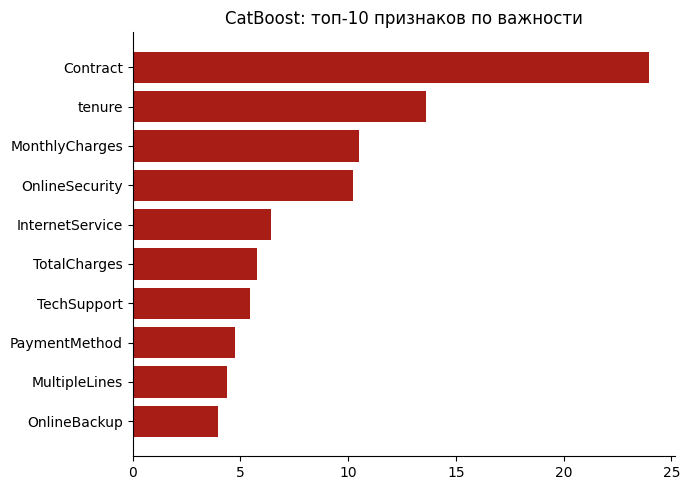

In [11]:
importances = pd.Series(cat.get_feature_importance(), index=X_tr_cb.columns).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(importances.index[-10:], importances.values[-10:], color="#A81E17")
plt.title("CatBoost: топ-10 признаков по важности")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

CatBoost выигрывает у логистической регрессии на сотые доли AUC. На таком датасете это ожидаемо: сигнал простой, сложная модель добавляет немного. Зато остановился он задолго до тысячной итерации: без ранней остановки мы бы обучали лишнее и переобучались.

## 8. Порог под бизнес-требование

`predict_proba` даёт вероятность, а решение «звонить клиенту или нет» требует порога. Порог 0.5 ничем не лучше других. Допустим, бизнес хочет ловить не меньше 70% уходящих: подбираем максимальный порог, при котором recall ≥ 0.7, и смотрим, какой ценой по precision это достигается.

порог 0.372: recall 0.701, precision 0.571


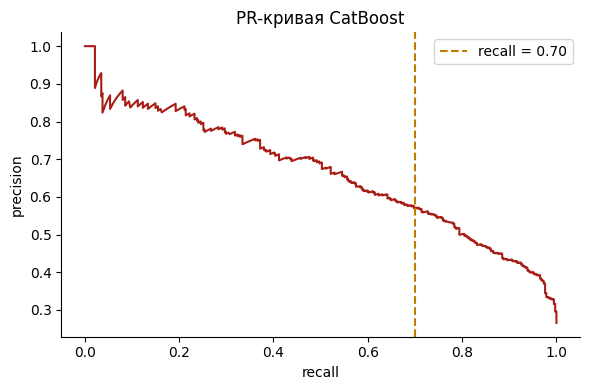

In [12]:
precision, recall, thresholds = precision_recall_curve(y_test, proba_cb)
mask = recall[:-1] >= 0.70
best_threshold = thresholds[mask].max()
pred = (proba_cb >= best_threshold).astype(int)
print(f"порог {best_threshold:.3f}: recall {recall_score(y_test, pred):.3f}, "
      f"precision {precision_score(y_test, pred):.3f}")

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="#A81E17")
plt.axvline(0.70, color="#C07C00", linestyle="--", label="recall = 0.70")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("PR-кривая CatBoost")
plt.legend(); plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Порог это часть модели, а не свойство данных. В сервисе он будет храниться рядом с весами в метаданных артефакта, и менять его можно без переобучения.

## 9. Сохранение артефакта с метаданными

Сохраняем не «веса», а всё, что нужно сервису, чтобы ответить на запрос: сам Pipeline (предобработка внутри), порог, список колонок и версии библиотек. Без этого через месяц никто не вспомнит, на чём модель обучалась.

In [13]:
import sklearn, catboost

metadata = {
    "model_name": "churn-baseline",
    "model_version": "0.1.0",
    "trained_at": pd.Timestamp.utcnow().isoformat(timespec="seconds"),
    "n_train": int(len(X_train)),
    "features": list(X.columns),
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "threshold": float(round(best_threshold, 4)),
    "metrics_test": {k: round(float(v), 4) for k, v in results[1].items() if k != "model"},
    "libs": {"pandas": pd.__version__, "scikit-learn": sklearn.__version__, "catboost": catboost.__version__},
}

joblib.dump({"pipeline": logreg, "metadata": {**metadata, "model_name": "churn-logreg"}},
            ARTIFACTS / "baseline_logreg.joblib")
cat.save_model(str(ARTIFACTS / "baseline_catboost.cbm"))
(ARTIFACTS / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

sorted(p.name for p in ARTIFACTS.iterdir())

['baseline_catboost.cbm', 'baseline_logreg.joblib', 'metadata.json']

## 10. Загрузка и предсказание на одной строке

Так будет выглядеть путь запроса в сервисе: одна строка приходит как словарь, превращается в датафрейм из одной строки, проходит через тот же Pipeline и возвращает вероятность. Никакого кода предобработки в сервисе не будет: он весь внутри артефакта.

In [14]:
bundle = joblib.load(ARTIFACTS / "baseline_logreg.joblib")
pipe, meta = bundle["pipeline"], bundle["metadata"]

payload = X_test.iloc[0].to_dict()          # так придёт запрос: dict
payload["TotalCharges"] = None if pd.isna(payload["TotalCharges"]) else payload["TotalCharges"]
frame = pd.DataFrame([payload])[meta["features"]]   # порядок колонок как при обучении

score = float(pipe.predict_proba(frame)[0, 1])
print(json.dumps({"score": round(score, 4),
                  "churn": bool(score >= meta["threshold"]),
                  "model_version": meta["model_version"]}, ensure_ascii=False))

{"score": 0.0453, "churn": false, "model_version": "0.1.0"}


In [15]:
# контроль: предсказание на одной строке совпадает с предсказанием на всём батче
batch_score = pipe.predict_proba(X_test)[0, 1]
assert abs(batch_score - score) < 1e-9, "train-serve skew: одна строка и батч дают разные ответы"
print("одна строка и батч совпадают до 1e-9")

одна строка и батч совпадают до 1e-9


## Что запомнить

- Пропуски и кодирование живут внутри `Pipeline`, поэтому обучение и сервис считают фичи одинаково
- При дисбалансе смотрим ROC-AUC и PR-AUC, а порог подбираем под требование бизнеса, не берём 0.5
- Ранняя остановка это защита от переобучения бустинга, а не оптимизация скорости
- Артефакт это Pipeline плюс метаданные: порог, колонки, версии библиотек
- Одна строка через Pipeline даёт то же, что батч. Этот assert станет тестом в вашем репозитории

В понедельник на лекции 1.1 разберём, почему `predict_proba` в ноутбуке это ещё не продукт, и что происходит с этим артефактом дальше.